# 6 · Prove: is the difference real, and is it fair?

**Syllabus:** Module 3 (estimation, hypothesis testing) and Module 6 (bias and
fairness, transparency, accountability).

Chapter 3 found that some models have lower error than others. A lower number is not
yet proof. With a different two years of floats, would the ranking hold? This chapter
answers with hypothesis tests, then asks whether the model serves both seas equally
well.

## The hypotheses, fixed before computing anything

For each of the 15 depths:

| Test | H₀ (null) | H₁ (alternative) |
|---|---|---|
| **A** | Satelight's error equals climatology's | They differ (two-sided) |
| **B** | Satelight's error equals the best course model's | They differ (two-sided) |
| **C** | Satelight's skill is the same in the Bay of Bengal and the Arabian Sea | It differs (two-sided) |

**Significance level:** α = 0.05, corrected for testing 15 depths at once (Holm's
method). Without the correction, 15 tests at 5% would give about a 54% chance of at
least one false "discovery".

**The unit of evidence is the float, not the measurement.** One float reports every
10 days along a slowly drifting path, so its casts are not independent. Counting 6,000
casts as 6,000 independent facts would make every test "significant". So:

* the tests compare per-float average errors (a paired t-test on floats), and
* confidence intervals come from a **bootstrap that resamples whole floats**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import common as C

C.style()
casts = C.load_casts()
course = pd.read_csv(C.ROOT / "results" / "course_predictions_argo.csv.gz")
casts = casts.merge(course, on="cast_id")
res = __import__("json").loads(C.RESULTS.read_text(encoding="utf-8"))
best_course = res["regression"]["best_course_model"]
obs = C.profiles(casts, "obs_")
M = {"Climatology": C.profiles(casts, "climatology|"), "Satelight hybrid": C.profiles(casts, "hybrid (selected)|"),
     best_course: C.profiles(casts, f"{best_course}|"), "GLORYS": C.profiles(casts, "GLORYS (ceiling)|")}
# The same points as chapter 3: where the cast and every model (Satelight's and ours) have a value.
pts = np.isfinite(obs)
for name in {c.split("|")[0] for c in casts.columns if "|" in c}:
    pts &= np.isfinite(C.profiles(casts, f"{name}|"))
floats = casts["platform"].astype(str).to_numpy()
uf, fidx = np.unique(floats, return_inverse=True)
print(f"Casts {len(casts):,} from {len(uf):,} floats; points scored {int(pts.sum()):,}. Best course model: {best_course}")
C.record("prove.floats", len(uf))

Casts 6,144 from 112 floats; points scored 88,829. Best course model: Polynomial


In [2]:
def per_float(model, mask=None):
    """Sum of squared errors and number of points, per float and depth: (F, 15) each."""
    se = np.where(pts, (M[model] - obs) ** 2, 0.0)
    n = pts.astype(float)
    if mask is not None:
        se, n = se * mask[:, None], n * mask[:, None]
    S, N = np.zeros((len(uf), 15)), np.zeros((len(uf), 15))
    np.add.at(S, fidx, se); np.add.at(N, fidx, n)
    return S, N


rng = np.random.default_rng(C.SEED)
W = rng.multinomial(len(uf), np.full(len(uf), 1 / len(uf)), size=2000).astype(float)   # 2,000 resamples of floats


def boot_rmse(S, N):
    return np.sqrt((W @ S) / (W @ N))                                                   # (2000, 15)


def holm(p):
    """Holm–Bonferroni adjusted p-values."""
    p = np.asarray(p); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[i])); adj[i] = running
    return adj


def compare(a, b):
    Sa, Na = per_float(a); Sb, Nb = per_float(b)
    rmse_a, rmse_b = np.sqrt(Sa.sum(0) / Na.sum(0)), np.sqrt(Sb.sum(0) / Nb.sum(0))
    diff_boot = boot_rmse(Sa, Na) - boot_rmse(Sb, Nb)
    lo, hi = np.percentile(diff_boot, [2.5, 97.5], axis=0)
    p = []
    for k in range(15):
        ok = Na[:, k] > 0
        p.append(stats.ttest_rel(Sa[ok, k] / Na[ok, k], Sb[ok, k] / Nb[ok, k]).pvalue)
    out = pd.DataFrame({"depth_m": C.DEPTHS, f"RMSE {a}": rmse_a, f"RMSE {b}": rmse_b, "difference": rmse_a - rmse_b,
                        "CI low": lo, "CI high": hi, "p": p, "p (Holm)": holm(p)})
    out["verdict"] = np.where(out["p (Holm)"] < 0.05, np.where(out["difference"] < 0, f"{a} better", f"{b} better"), "no significant difference")
    return out.round(4)

## Test A: is Satelight better than climatology?

In [3]:
A = compare("Satelight hybrid", "Climatology")
C.record("prove.test_A", A.to_dict("records"))
A

,depth_m,RMSE Satelight hybrid,RMSE Climatology,difference,CI low,CI high,p,p (Holm),verdict
0,0,0.5428,0.8692,-0.3264,-0.3642,-0.2889,0.0000,0.0000,Satelight hybrid better
1,5,0.5425,0.8827,-0.3402,-0.3803,-0.2986,0.0000,0.0000,Satelight hybrid better
2,10,0.6294,0.9268,-0.2974,-0.3507,-0.2515,0.0000,0.0000,Satelight hybrid better
3,20,0.8248,1.0555,-0.2306,-0.3036,-0.1695,0.0000,0.0000,Satelight hybrid better
4,30,0.9764,1.1941,-0.2176,-0.2840,-0.1522,0.0000,0.0000,Satelight hybrid better
5,50,1.1307,1.3828,-0.2521,-0.3209,-0.1889,0.0000,0.0000,Satelight hybrid better
6,75,1.3424,1.6888,-0.3464,-0.4540,-0.2471,0.0000,0.0000,Satelight hybrid better
7,100,1.5868,1.8647,-0.2779,-0.3976,-0.1650,0.0000,0.0001,Satelight hybrid better
8,125,1.4493,1.6795,-0.2302,-0.3381,-0.1209,0.0005,0.0026,Satelight hybrid better
9,150,1.1395,1.3649,-0.2254,-0.3186,-0.1291,0.0002,0.0013,Satelight hybrid better


## Test B: is Satelight better than the best course method?

In [4]:
B = compare("Satelight hybrid", best_course)
C.record("prove.test_B", B.to_dict("records"))
B

,depth_m,RMSE Satelight hybrid,RMSE Polynomial,difference,CI low,CI high,p,p (Holm),verdict
0,0,0.5428,0.4763,0.0665,0.0315,0.1033,0.0018,0.0264,Polynomial better
1,5,0.5425,0.4764,0.0661,0.0344,0.0976,0.0070,0.0986,no significant difference
2,10,0.6294,0.5827,0.0467,0.0206,0.0716,0.0104,0.1349,no significant difference
3,20,0.8248,0.8310,-0.0061,-0.0248,0.0136,0.7645,1.0000,no significant difference
4,30,0.9764,0.9999,-0.0234,-0.0563,0.0155,0.1948,1.0000,no significant difference
5,50,1.1307,1.1535,-0.0228,-0.0796,0.0362,0.3088,1.0000,no significant difference
6,75,1.3424,1.3654,-0.0230,-0.0717,0.0244,0.6508,1.0000,no significant difference
7,100,1.5868,1.5752,0.0116,-0.0270,0.0521,0.8519,1.0000,no significant difference
8,125,1.4493,1.4517,-0.0024,-0.0410,0.0390,0.1830,1.0000,no significant difference
9,150,1.1395,1.1587,-0.0192,-0.0517,0.0153,0.0259,0.2847,no significant difference


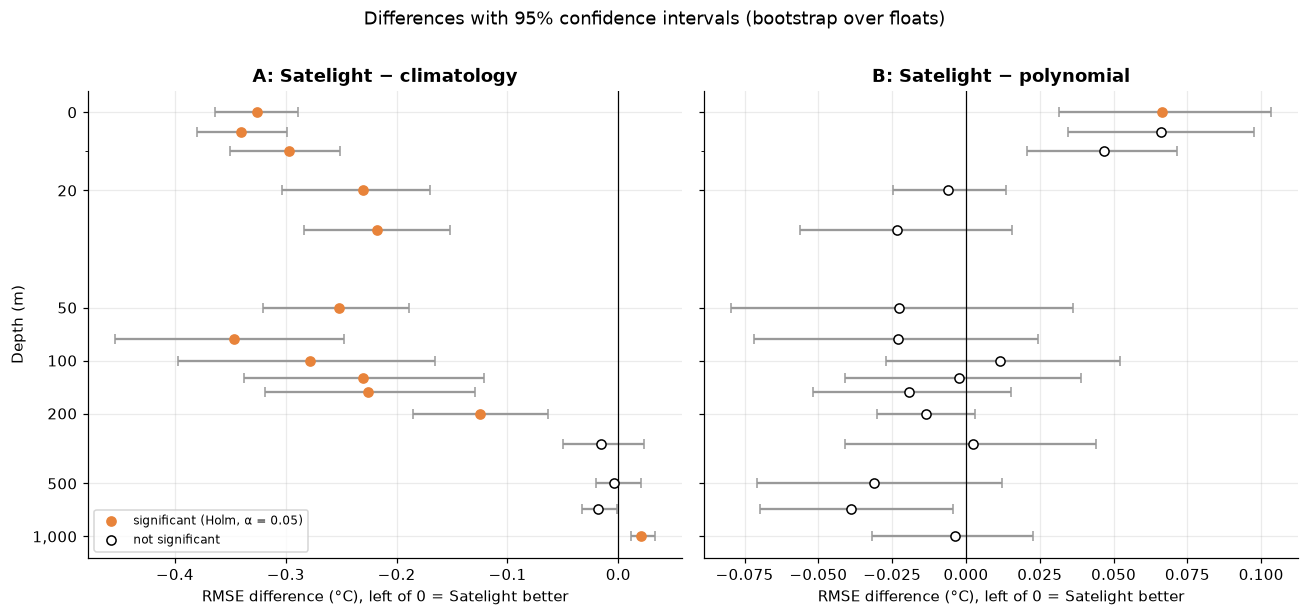

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
for ax, T, title in [(axes[0], A, "A: Satelight − climatology"), (axes[1], B, f"B: Satelight − {best_course.lower()}")]:
    sig = T["p (Holm)"] < 0.05
    ax.errorbar(T["difference"], T["depth_m"], xerr=[T["difference"] - T["CI low"], T["CI high"] - T["difference"]],
                fmt="none", ecolor="#999", capsize=3)
    ax.scatter(T.loc[sig, "difference"], T.loc[sig, "depth_m"], color=C.PALETTE["deep"], zorder=3, label="significant (Holm, α = 0.05)")
    ax.scatter(T.loc[~sig, "difference"], T.loc[~sig, "depth_m"], facecolor="white", edgecolor="k", zorder=3, label="not significant")
    ax.axvline(0, color="k", lw=0.8); ax.set_title(title); ax.set_xlabel("RMSE difference (°C), left of 0 = Satelight better")
    ax.set_yscale("symlog", linthresh=50); ax.set_yticks([0, 20, 50, 100, 200, 500, 1000]); ax.set_yticklabels([0, 20, 50, 100, 200, 500, "1,000"])
axes[0].invert_yaxis(); axes[0].set_ylabel("Depth (m)"); axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Differences with 95% confidence intervals (bootstrap over floats)", y=1.01)
fig.tight_layout(); C.save(fig, "prove_tests")

A dot with its whole interval left of zero means Satelight is better at that depth with
95% confidence. An interval crossing zero means the data cannot tell the two models
apart there, whatever the raw numbers say. A dot right of zero is a depth where
Satelight is significantly *worse*, and an honest report says so.

## Test C: fairness between the two seas

Raw RMSE cannot answer whether the model is fair. The Bay of Bengal has a sharper
thermocline, so *every* model, even climatology, has larger errors there. Comparing
raw errors would confuse "harder sea" with "worse model". So we compare **skill**:

skill = 1 − MSE(model) / MSE(climatology)

0 means no better than climatology and 1 means perfect, measured against what is
achievable in each sea.

In [6]:
bay = casts["basin"].eq("Bay of Bengal").to_numpy()
arab = casts["basin"].eq("Arabian Sea").to_numpy()


def skill_boot(model, mask):
    Sm, Nm = per_float(model, mask); Sc, Nc = per_float("Climatology", mask)
    point = 1 - (Sm.sum(0) / Nm.sum(0)) / (Sc.sum(0) / Nc.sum(0))
    with np.errstate(invalid="ignore", divide="ignore"):
        boot = 1 - (W @ Sm / (W @ Nm)) / (W @ Sc / (W @ Nc))
    return point, boot


fair = []
for model in ["Satelight hybrid", best_course]:
    pb, bb = skill_boot(model, bay); pa, ba = skill_boot(model, arab)
    d = bb - ba
    p_boot = np.minimum(1, 2 * np.minimum(np.nanmean(d <= 0, axis=0), np.nanmean(d >= 0, axis=0)))
    for k, z in enumerate(C.DEPTHS):
        fair.append({"model": model, "depth_m": z, "skill Bay": pb[k], "skill Arabian": pa[k], "difference": pb[k] - pa[k],
                     "CI low": np.nanpercentile(d[:, k], 2.5), "CI high": np.nanpercentile(d[:, k], 97.5), "p": p_boot[k]})
fair = pd.DataFrame(fair)
fair["p (Holm)"] = fair.groupby("model")["p"].transform(lambda p: holm(p.to_numpy()))
fair = fair.round(4)
C.record("prove.test_C", fair.to_dict("records"))
fair[fair["model"] == "Satelight hybrid"]

,model,depth_m,skill Bay,skill Arabian,difference,CI low,CI high,p,p (Holm)
0,Satelight hybrid,0,0.6993,0.6009,0.0983,-0.0035,0.1934,0.056,0.336
1,Satelight hybrid,5,0.7396,0.6137,0.1259,0.0230,0.2245,0.006,0.054
2,Satelight hybrid,10,0.7340,0.5124,0.2216,0.0698,0.3305,0.003,0.039
3,Satelight hybrid,20,0.5856,0.3525,0.2331,0.0358,0.3661,0.015,0.120
4,Satelight hybrid,30,0.3475,0.3053,0.0422,-0.1133,0.1766,0.618,1.000
5,Satelight hybrid,50,0.4279,0.3216,0.1062,-0.0287,0.2311,0.120,0.600
6,Satelight hybrid,75,0.5119,0.2895,0.2223,0.0686,0.3734,0.004,0.048
7,Satelight hybrid,100,0.5021,0.1487,0.3534,0.1939,0.5293,0.000,0.000
8,Satelight hybrid,125,0.4773,0.1462,0.3310,0.1590,0.5291,0.000,0.000
9,Satelight hybrid,150,0.4624,0.2378,0.2246,0.0734,0.4178,0.005,0.050


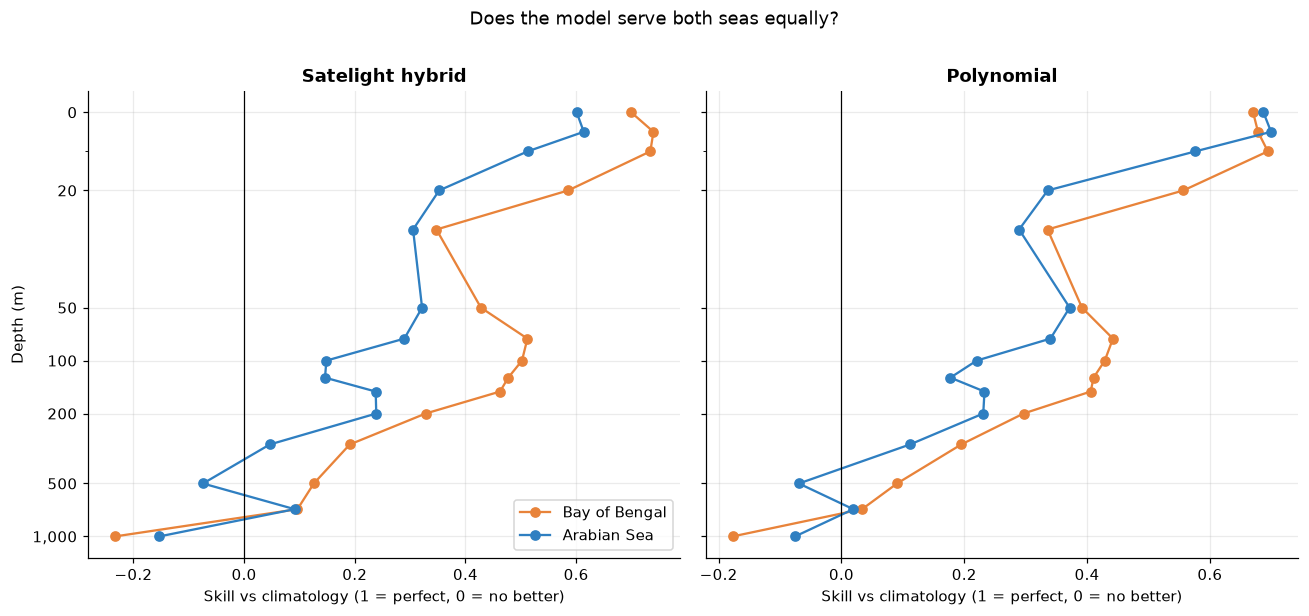

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
for ax, model in zip(axes, ["Satelight hybrid", best_course]):
    f = fair[fair["model"] == model]
    ax.plot(f["skill Bay"], f["depth_m"], marker="o", color=C.PALETTE["deep"], label="Bay of Bengal")
    ax.plot(f["skill Arabian"], f["depth_m"], marker="o", color=C.PALETTE["course"], label="Arabian Sea")
    ax.axvline(0, color="k", lw=0.8); ax.set_title(model); ax.set_xlabel("Skill vs climatology (1 = perfect, 0 = no better)")
    ax.set_yscale("symlog", linthresh=50); ax.set_yticks([0, 20, 50, 100, 200, 500, 1000]); ax.set_yticklabels([0, 20, 50, 100, 200, 500, "1,000"])
axes[0].invert_yaxis(); axes[0].set_ylabel("Depth (m)"); axes[0].legend()
fig.suptitle("Does the model serve both seas equally?", y=1.01)
fig.tight_layout(); C.save(fig, "prove_fairness")

## Representation: who is in the data?

Fairness also depends on how much evidence each place contributes. If one sea has far
fewer floats, the model is both trained and judged with less information there.

In [8]:
rep = casts.groupby("basin").agg(casts=("cast_id", "size"), floats=("platform", "nunique"))
area = pd.Series({b: (v["lon"][1] - v["lon"][0]) * (v["lat"][1] - v["lat"][0]) for b, v in C.BASINS.items()})
rep["box area (deg²)"] = area
rep["casts per 100 deg²"] = (100 * rep["casts"] / rep["box area (deg²)"]).round(1)
C.record("prove.representation", rep.drop(index="Other", errors="ignore").to_dict(orient="index"))
rep

,casts,floats,box area (deg²),casts per 100 deg²
basin,,,,
Arabian Sea,4428,76,567.0,781.0
Bay of Bengal,1341,37,396.0,338.6
Other,375,9,NaN,NaN


## Transparency and accountability: the data's paper trail

Every measurement in this project carries where it came from and how much it can be
trusted. That is what makes the numbers above checkable.

In [9]:
trail = {"casts": len(casts), "data_mode": casts["data_mode"].value_counts().to_dict(),
         "levels_rejected_by_qc": int(casts["levels_rejected"].sum()),
         "casts_with_any_rejected_level": int((casts["levels_rejected"] > 0).sum()),
         "source_files": int(casts["source_file"].nunique())}
C.record("prove.paper_trail", trail)
trail

{'casts': 6144,
 'data_mode': {'D': 5136, 'A': 576, 'R': 432},
 'levels_rejected_by_qc': 1172,
 'casts_with_any_rejected_level': 289,
 'source_files': 6144}

* **Data mode:** D (delayed mode) means a scientist checked and corrected the
  profile; A means automatically adjusted; R is raw real-time data.
* **Rejected levels are counted, never hidden:** a measurement failing QC is excluded
  from scoring, and the count is reported.
* **Every number in this project is written by the code that computed it** into one
  results file. The dashboard and the report read that file and nothing is typed by
  hand, so any figure can be traced back to the notebook cell that produced it.